In [2]:
import os
import re
from datetime import datetime
import numpy as np
import pandas as pd
from openpyxl.styles import Font, PatternFill, Alignment

# 1. Xác định đường dẫn thư mục Data
raw_dir = "../Data/raw" if os.path.exists("../Data/raw") else ("../data/raw" if os.path.exists("../data/raw") else "Data/raw")
proc_dir = "../Data/processed" if os.path.exists("../Data") else ("../data/processed" if os.path.exists("../data") else "Data/processed")
os.makedirs(proc_dir, exist_ok=True)

now_str = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# ==============================================================================
# CÁC HÀM CHUẨN HÓA DỮ LIỆU
# ==============================================================================
HANOI_DISTRICTS = [
    "Ba Đình", "Hoàn Kiếm", "Tây Hồ", "Long Biên", "Cầu Giấy", "Đống Đa",
    "Hai Bà Trưng", "Hoàng Mai", "Thanh Xuân", "Nam Từ Liêm", "Bắc Từ Liêm",
    "Hà Đông", "Sơn Tây", "Ba Vì", "Chương Mỹ", "Đan Phượng", "Đông Anh",
    "Gia Lâm", "Hoài Đức", "Mê Linh", "Mỹ Đức", "Phú Xuyên", "Phúc Thọ",
    "Quốc Oai", "Sóc Sơn", "Thạch Thất", "Thanh Oai", "Thanh Trì", "Thường Tín", "Ứng Hòa"
]

def normalize_district(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    low = s.lower()
    for d in HANOI_DISTRICTS:
        if d.lower() in low:
            return d
    return np.nan

def normalize_house_type(val):
    if pd.isna(val):
        return np.nan
    low = str(val).lower()
    if "chung cư" in low or "căn hộ" in low:
        return "Chung cư"
    if "biệt thự" in low or "liền kề" in low:
        return "Biệt thự liền kề"
    if "mặt phố" in low or "mặt tiền" in low:
        return "Nhà mặt phố"
    if "đất" in low:
        return "Đất nền"
    if "nhà" in low or "ngõ" in low or "hẻm" in low or "riêng" in low:
        return "Nhà riêng"
    return "Nhà riêng"

def parse_float(val):
    if pd.isna(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    s = str(val).lower().replace(",", ".")
    m = re.search(r"(\d+(?:\.\d+)?)", s)
    return float(m.group(1)) if m else np.nan

def parse_int(val):
    f = parse_float(val)
    return int(round(f)) if pd.notna(f) else np.nan

def parse_price_to_vnd(raw_text, area_m2=np.nan):
    """Quy đổi giá gốc dạng văn bản sang VNĐ."""
    if pd.isna(raw_text):
        return np.nan
    s = str(raw_text).lower().strip()
    if not s or any(k in s for k in ["thỏa thuận", "thoả thuận", "liên hệ", "nan"]):
        return np.nan

    s_clean = s.replace(",", ".")
    # Dạng "X tỷ Y triệu" (VD: 5 tỷ 200 triệu)
    m_ty_tr = re.search(r"(\d+(?:\.\d+)?)\s*tỷ\s*(\d+(?:\.\d+)?)\s*triệu", s_clean)
    if m_ty_tr:
        return float(m_ty_tr.group(1)) * 1e9 + float(m_ty_tr.group(2)) * 1e6

    m_num = re.search(r"(\d+(?:\.\d+)?)", s_clean)
    if not m_num:
        return np.nan
    num = float(m_num.group(1))

    is_per_m2 = "/m" in s_clean or "m2" in s_clean or "m²" in s_clean
    if "tỷ" in s_clean:
        val = num * 1e9
    elif "triệu" in s_clean or "tr" in s_clean:
        val = num * 1e6
    elif num > 1e7:
        val = num
    elif num < 1000:
        val = num * 1e9
    else:
        val = num * 1e6

    if is_per_m2:
        return val * area_m2 if (pd.notna(area_m2) and area_m2 > 0) else np.nan
    return val

# ==============================================================================
# 2. ĐỌC & CHUẨN HÓA TỪNG NGUỒN VỀ CHUNG CẤU TRÚC
# ==============================================================================
# --- NGUỒN 1: DỮ LIỆU TỰ CRAWL (1.152 bản ghi) ---
df_crawl_raw = pd.read_csv(os.path.join(raw_dir, "crawled_hanoi.csv"))
df_crawl = pd.DataFrame()
df_crawl["Nguồn dữ liệu"] = df_crawl_raw["Nguồn dữ liệu"]
df_crawl["Mã bản ghi theo nguồn"] = df_crawl_raw["Mã bản ghi theo nguồn"].astype(str)
df_crawl["Link trang tổng"] = df_crawl_raw["Link trang tổng"]
df_crawl["Link trang con"] = df_crawl_raw["Link trang con"]
df_crawl["Thời điểm thu thập"] = df_crawl_raw["Thời điểm thu thập"].fillna(now_str)
df_crawl["Tiêu đề"] = df_crawl_raw["Tiêu đề"]
df_crawl["Ngày đăng"] = df_crawl_raw["Ngày đăng"]
df_crawl["Mô tả"] = df_crawl_raw["Mô tả"]
df_crawl["Thành phố"] = "Hà Nội"
df_crawl["Khu vực/Quận huyện theo nguồn"] = df_crawl_raw["Khu vực/Quận huyện theo nguồn"].apply(normalize_district)
df_crawl["Phường xã"] = df_crawl_raw["Phường xã"]
df_crawl["Tên dự án nếu có"] = df_crawl_raw["Tên dự án nếu có"]
df_crawl["Loại nhà"] = df_crawl_raw["Loại nhà"].apply(normalize_house_type)
df_crawl["Diện tích"] = df_crawl_raw["Diện tích"].apply(parse_float)
df_crawl["Số tầng"] = df_crawl_raw["Số tầng"].apply(parse_int)
df_crawl["Số phòng ngủ"] = df_crawl_raw["Số phòng ngủ"].apply(parse_int)
df_crawl["Số phòng vệ sinh"] = df_crawl_raw["Số phòng vệ sinh"].apply(parse_int)
df_crawl["Giá gốc dạng văn bản"] = df_crawl_raw["Giá gốc dạng văn bản"]
df_crawl["Giá chuẩn hóa VNĐ"] = [
    parse_price_to_vnd(p, a) for p, a in zip(df_crawl["Giá gốc dạng văn bản"], df_crawl["Diện tích"])
]

# --- NGUỒN 2: HUGGING FACE ---
df_hf_raw = pd.read_csv(os.path.join(raw_dir, "hf_hanoi.csv"))
if "province_name" in df_hf_raw.columns:
    hn_mask = df_hf_raw["province_name"].astype(str).str.contains("Hà Nội|Ha Noi", case=False, na=False)
    if hn_mask.sum() >= 50:
        df_hf_raw = df_hf_raw[hn_mask].copy()

df_hf = pd.DataFrame(index=df_hf_raw.index)
df_hf["Nguồn dữ liệu"] = "HuggingFace_VN_RealEstate"
df_hf["Mã bản ghi theo nguồn"] = [f"HF_{i+1:05d}" for i in range(len(df_hf_raw))]
df_hf["Link trang tổng"] = "https://huggingface.co/datasets/sarahooker/vietnam-real-estate-listings"
df_hf["Link trang con"] = np.nan  # Theo quy ước: dataset không có link tin con
df_hf["Thời điểm thu thập"] = df_hf_raw["collected_at"] if "collected_at" in df_hf_raw.columns else now_str
df_hf["Tiêu đề"] = df_hf_raw["name"] if "name" in df_hf_raw.columns else df_hf_raw.get("title", np.nan)
df_hf["Ngày đăng"] = df_hf_raw["published_at"] if "published_at" in df_hf_raw.columns else np.nan
df_hf["Mô tả"] = df_hf_raw["description"] if "description" in df_hf_raw.columns else np.nan
df_hf["Thành phố"] = "Hà Nội"
dist_col_hf = df_hf_raw["district_name"] if "district_name" in df_hf_raw.columns else df_hf_raw.get("district", np.nan)
df_hf["Khu vực/Quận huyện theo nguồn"] = pd.Series(dist_col_hf).apply(normalize_district)
df_hf["Phường xã"] = df_hf_raw["ward_name"] if "ward_name" in df_hf_raw.columns else np.nan
df_hf["Tên dự án nếu có"] = df_hf_raw["project_name"] if "project_name" in df_hf_raw.columns else np.nan
type_col_hf = df_hf_raw["property_type_name"] if "property_type_name" in df_hf_raw.columns else df_hf_raw.get("property_type", np.nan)
df_hf["Loại nhà"] = pd.Series(type_col_hf).apply(normalize_house_type)
df_hf["Diện tích"] = pd.Series(df_hf_raw["area"] if "area" in df_hf_raw.columns else df_hf_raw.get("area_m2", np.nan)).apply(parse_float)
df_hf["Số tầng"] = pd.Series(df_hf_raw["floor_count"] if "floor_count" in df_hf_raw.columns else np.nan).apply(parse_int)
df_hf["Số phòng ngủ"] = pd.Series(df_hf_raw["bedroom_count"] if "bedroom_count" in df_hf_raw.columns else np.nan).apply(parse_int)
df_hf["Số phòng vệ sinh"] = pd.Series(df_hf_raw["bathroom_count"] if "bathroom_count" in df_hf_raw.columns else np.nan).apply(parse_int)

raw_hf_price = df_hf_raw["price"] if "price" in df_hf_raw.columns else df_hf_raw.get("raw_price_text", np.nan)
df_hf["Giá chuẩn hóa VNĐ"] = [parse_price_to_vnd(p, a) for p, a in zip(raw_hf_price, df_hf["Diện tích"])]
df_hf["Giá gốc dạng văn bản"] = df_hf["Giá chuẩn hóa VNĐ"].apply(
    lambda x: f"{round(x/1e9, 2)} tỷ" if pd.notna(x) else np.nan
)

# --- NGUỒN 3: KAGGLE (Lấy mẫu 9.500 bản ghi để tổng quy mô ~11.000 dòng trong khung 5.000-15.000) ---
df_kg_full = pd.read_csv(os.path.join(raw_dir, "kaggle_hanoi.csv"))
df_kg_raw = df_kg_full.sample(n=min(9500, len(df_kg_full)), random_state=42).reset_index(drop=True)

df_kg = pd.DataFrame(index=df_kg_raw.index)
df_kg["Nguồn dữ liệu"] = "Kaggle_Vietnam_Housing"
df_kg["Mã bản ghi theo nguồn"] = [f"KG_{i+1:05d}" for i in range(len(df_kg_raw))]
df_kg["Link trang tổng"] = "https://www.kaggle.com/datasets/ladcva/vietnam-housing-dataset-hanoi"
df_kg["Link trang con"] = np.nan  # Theo quy ước: dataset không có link tin con
df_kg["Thời điểm thu thập"] = df_kg_raw["collected_at"] if "collected_at" in df_kg_raw.columns else now_str

raw_dist_kg = df_kg_raw["Quận"].fillna(df_kg_raw["Huyện"]) if ("Quận" in df_kg_raw.columns and "Huyện" in df_kg_raw.columns) else df_kg_raw.get("Địa chỉ", np.nan)
dist_kg_norm = pd.Series(raw_dist_kg).apply(normalize_district)

def extract_ward_from_addr(addr):
    if pd.isna(addr):
        return np.nan
    m = re.search(r"(?:Phường|Xã|Thị trấn)\s+([^,]+)", str(addr), re.IGNORECASE)
    return m.group(1).strip() if m else np.nan

ward_kg = df_kg_raw["Địa chỉ"].apply(extract_ward_from_addr) if "Địa chỉ" in df_kg_raw.columns else np.nan
type_kg = df_kg_raw["Loại hình nhà ở"].apply(normalize_house_type) if "Loại hình nhà ở" in df_kg_raw.columns else "Nhà riêng"
area_kg = df_kg_raw["Diện tích"].apply(parse_float) if "Diện tích" in df_kg_raw.columns else np.nan

df_kg["Tiêu đề"] = (
    "Bán " + type_kg.fillna("Nhà ở").astype(str) + " "
    + area_kg.fillna(0).round(1).astype(str) + "m² tại "
    + dist_kg_norm.fillna("Hà Nội").astype(str)
)
df_kg["Ngày đăng"] = df_kg_raw["Ngày"] if "Ngày" in df_kg_raw.columns else np.nan
df_kg["Mô tả"] = df_kg_raw["Địa chỉ"] if "Địa chỉ" in df_kg_raw.columns else np.nan
df_kg["Thành phố"] = "Hà Nội"
df_kg["Khu vực/Quận huyện theo nguồn"] = dist_kg_norm
df_kg["Phường xã"] = ward_kg
df_kg["Tên dự án nếu có"] = np.nan
df_kg["Loại nhà"] = type_kg
df_kg["Diện tích"] = area_kg
df_kg["Số tầng"] = df_kg_raw["Số tầng"].apply(parse_int) if "Số tầng" in df_kg_raw.columns else np.nan
df_kg["Số phòng ngủ"] = df_kg_raw["Số phòng ngủ"].apply(parse_int) if "Số phòng ngủ" in df_kg_raw.columns else np.nan
df_kg["Số phòng vệ sinh"] = np.nan  # Giữ nguyên thực tế từ nguồn (không bịa số liệu)

raw_price_kg = df_kg_raw["Giá/m2"] if "Giá/m2" in df_kg_raw.columns else df_kg_raw.get("raw_price_text", np.nan)
df_kg["Giá gốc dạng văn bản"] = raw_price_kg
df_kg["Giá chuẩn hóa VNĐ"] = [parse_price_to_vnd(p, a) for p, a in zip(raw_price_kg, df_kg["Diện tích"])]

# ==============================================================================
# 3. HỢP NHẤT & GẮN 3 CỘT CỜ CHẤT LƯỢNG DỮ LIỆU
# ==============================================================================
df_all = pd.concat([df_crawl, df_hf, df_kg], ignore_index=True)
df_all.insert(0, "Mã bản ghi", [f"HN_{i+1:06d}" for i in range(len(df_all))])

# Cờ 1: Cờ trùng lặp (trùng Link trang con khi có link, hoặc trùng tổ hợp Quận + Loại nhà + Diện tích + Giá + Tiêu đề)
dup_url = df_all["Link trang con"].notna() & df_all.duplicated(subset=["Link trang con"], keep="first")
dup_content = df_all.duplicated(
    subset=["Khu vực/Quận huyện theo nguồn", "Loại nhà", "Diện tích", "Giá chuẩn hóa VNĐ", "Tiêu đề"],
    keep="first"
)
df_all["Cờ trùng lặp"] = np.where(dup_url | dup_content, 1, 0)

# Cờ 2: Cờ thiếu dữ liệu (thiếu các trường lõi: Quận/Huyện, Loại nhà, Diện tích, Giá chuẩn hóa VNĐ)
missing_core = (
    df_all["Khu vực/Quận huyện theo nguồn"].isna()
    | df_all["Loại nhà"].isna()
    | df_all["Diện tích"].isna()
    | df_all["Giá chuẩn hóa VNĐ"].isna()
)
df_all["Cờ thiếu dữ liệu"] = np.where(missing_core, 1, 0)

# Cờ 3: Cờ bất thường (diện tích, tổng giá, đơn giá/m2, số tầng/phòng ngủ vượt ngưỡng thực tế Hà Nội)
unit_price = df_all["Giá chuẩn hóa VNĐ"] / df_all["Diện tích"]
is_anom = (
    (df_all["Diện tích"] < 10) | (df_all["Diện tích"] > 1000)
    | (df_all["Giá chuẩn hóa VNĐ"] < 3e8) | (df_all["Giá chuẩn hóa VNĐ"] > 5e11)
    | (unit_price < 5e6) | (unit_price > 1.5e9)
    | (df_all["Số tầng"] > 15)
    | (df_all["Số phòng ngủ"] > 20)
)
df_all["Cờ bất thường"] = np.where(is_anom.fillna(False), 1, 0)

# Khóa đúng thứ tự 23 cột tiếng Việt chuẩn đề bài & mentor
FINAL_23_COLS = [
    "Mã bản ghi",
    "Nguồn dữ liệu",
    "Mã bản ghi theo nguồn",
    "Link trang tổng",
    "Link trang con",
    "Thời điểm thu thập",
    "Tiêu đề",
    "Ngày đăng",
    "Mô tả",
    "Thành phố",
    "Khu vực/Quận huyện theo nguồn",
    "Phường xã",
    "Tên dự án nếu có",
    "Loại nhà",
    "Diện tích",
    "Số tầng",
    "Số phòng ngủ",
    "Số phòng vệ sinh",
    "Giá gốc dạng văn bản",
    "Giá chuẩn hóa VNĐ",
    "Cờ trùng lặp",
    "Cờ thiếu dữ liệu",
    "Cờ bất thường",
]
df_all = df_all[FINAL_23_COLS]

# ==============================================================================
# 4. XUẤT FILE EXCEL DUY NHẤT 1 SHEET & LƯU BẢN SẠCH CHO ML/EDA
# ==============================================================================
excel_path = os.path.join(proc_dir, "hanoi_housing_data.xlsx")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    df_all.to_excel(writer, sheet_name="Du_Lieu_Nha_O_Ha_Noi", index=False)
    ws = writer.sheets["Du_Lieu_Nha_O_Ha_Noi"]

    # Định dạng tiêu đề & cột Giá chuẩn hóa VNĐ
    header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
    header_font = Font(color="FFFFFF", bold=True)
    for cell in ws[1]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(horizontal="center", vertical="center")

    price_col_idx = FINAL_23_COLS.index("Giá chuẩn hóa VNĐ") + 1
    for row in range(2, len(df_all) + 2):
        c = ws.cell(row=row, column=price_col_idx)
        if isinstance(c.value, (int, float)):
            c.number_format = "#,##0"

# Lưu thêm bản dữ liệu sạch (cờ = 0) dạng CSV để phục vụ Power BI & Bước 4 Machine Learning
df_clean = df_all[
    (df_all["Cờ trùng lặp"] == 0)
    & (df_all["Cờ thiếu dữ liệu"] == 0)
    & (df_all["Cờ bất thường"] == 0)
].copy()
clean_csv_path = os.path.join(proc_dir, "hanoi_housing_cleaned.csv")
df_clean.to_csv(clean_csv_path, index=False, encoding="utf-8-sig")

print(f"🎉 ĐÃ XUẤT FILE EXCEL 1 SHEET: {excel_path}")
print(f"   • Tổng số bản ghi hợp nhất: {len(df_all):,} dòng × {len(df_all.columns)} cột")
print(f"   • Phân bố theo nguồn:\n{df_all['Nguồn dữ liệu'].value_counts().to_string()}")
print("\n📊 THỐNG KÊ CHẤT LƯỢNG DỮ LIỆU (3 CỘT CỜ):")
print(f"   • Cờ trùng lặp (=1):     {df_all['Cờ trùng lặp'].sum():,} bản ghi")
print(f"   • Cờ thiếu dữ liệu (=1): {df_all['Cờ thiếu dữ liệu'].sum():,} bản ghi")
print(f"   • Cờ bất thường (=1):    {df_all['Cờ bất thường'].sum():,} bản ghi")
print(f"   • Bản ghi sạch hoàn toàn (cả 3 cờ = 0): {len(df_clean):,} bản ghi (đã lưu tại {clean_csv_path})")
display(df_all.head(3))

🎉 ĐÃ XUẤT FILE EXCEL 1 SHEET: ../Data/processed\hanoi_housing_data.xlsx
   • Tổng số bản ghi hợp nhất: 10,774 dòng × 23 cột
   • Phân bố theo nguồn:
Nguồn dữ liệu
Kaggle_Vietnam_Housing       9500
Crawl_Alonhadat.com.vn       1102
HuggingFace_VN_RealEstate     122
Crawl_Batdongsan.com.vn        50

📊 THỐNG KÊ CHẤT LƯỢNG DỮ LIỆU (3 CỘT CỜ):
   • Cờ trùng lặp (=1):     2,206 bản ghi
   • Cờ thiếu dữ liệu (=1): 1,118 bản ghi
   • Cờ bất thường (=1):    200 bản ghi
   • Bản ghi sạch hoàn toàn (cả 3 cờ = 0): 7,365 bản ghi (đã lưu tại ../Data/processed\hanoi_housing_cleaned.csv)


,Mã bản ghi,Nguồn dữ liệu,Mã bản ghi theo nguồn,Link trang tổng,Link trang con,Thời điểm thu thập,Tiêu đề,Ngày đăng,Mô tả,Thành phố,...,Loại nhà,Diện tích,Số tầng,Số phòng ngủ,Số phòng vệ sinh,Giá gốc dạng văn bản,Giá chuẩn hóa VNĐ,Cờ trùng lặp,Cờ thiếu dữ liệu,Cờ bất thường
0,HN_000001,Crawl_Batdongsan.com.vn,46453503,https://batdongsan.com.vn/ban-nha-dat-ha-noi,https://batdongsan.com.vn/ban-nha-rieng-phuong...,2026-11-17 13:57:27,"Tôi là chủ, cập nhật giá mới: Cần bán đất tặng...",17/11/2026,"* 108.9m², trung tâm lõi Quận Đống Đa, giá thư...",Hà Nội,...,Biệt thự liền kề,108.9,NaN,4.0,3.0,21 tỷ,2.100000e+10,0,0,0
1,HN_000002,Crawl_Batdongsan.com.vn,46532108,https://batdongsan.com.vn/ban-nha-dat-ha-noi,https://batdongsan.com.vn/ban-nha-biet-thu-lie...,2026-11-17 13:57:27,"Bán gấp biệt thự Ciputra 230m2 mặt đường 30m, ...",16/11/2026,* Cập nhật liên tục các căn biệt thự Ciputra m...,Hà Nội,...,Biệt thự liền kề,230.0,NaN,NaN,NaN,"66,7 tỷ",6.670000e+10,0,0,0
2,HN_000003,Crawl_Batdongsan.com.vn,46471426,https://batdongsan.com.vn/ban-nha-dat-ha-noi,https://batdongsan.com.vn/ban-shophouse-nha-ph...,2026-11-17 13:57:27,CĐT bán shop LK từ 90m2 Vin Cổ Loa trục cầu Tứ...,15/11/2026,Chủ đầu tư mở bán tháng 11 căn VIP phân khu Ce...,Hà Nội,...,Nhà riêng,90.0,NaN,6.0,6.0,"12,4 tỷ",1.240000e+10,0,0,0


BÁO CÁO PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA) - TRẢ LỜI 8 CÂU HỎI ĐỀ BÀI
1. Khoảng giá rao bán chủ yếu (IQR 25% - 75%): 2.80 tỷ – 5.80 tỷ VNĐ (Trung vị: 3.80 tỷ VNĐ).
2. Khu vực có giá/m² trung vị cao nhất: Hoàn Kiếm (177.2 triệu/m²).
3. Tương quan giữa Diện tích và Tổng giá: r = 0.606 (tương quan thuận).
4. Giá trung vị (Tỷ VNĐ) theo nhóm số phòng ngủ:
   1 PN: 3.00 tỷ | 2 PN: 2.60 tỷ | 3 PN: 3.10 tỷ | 4 PN: 4.00 tỷ | 5 PN: 4.80 tỷ | 6+ PN: 6.10 tỷ
5. Phân bố giá (Tỷ VNĐ) giữa các nguồn dữ liệu:
                           count  median   mean
Nguồn dữ liệu                                  
Crawl_Batdongsan.com.vn       45   20.00  34.40
HuggingFace_VN_RealEstate    111    9.80  16.91
Kaggle_Vietnam_Housing      7209    3.75   5.43
6. Cột thiếu nhiều dữ liệu nhất (trên 10,774 dòng hợp nhất): 'Tên dự án nếu có' (99.6%).
7. Kết quả lọc chất lượng: Ban đầu 10,774 | Trùng lặp: 2,206 | Thiếu dữ liệu: 1,118 | Bất thường: 200 -> Giữ lại 7,365 tin sạch.
8. [Mở rộng] Đơn giá/m² trung vị theo Loại nh

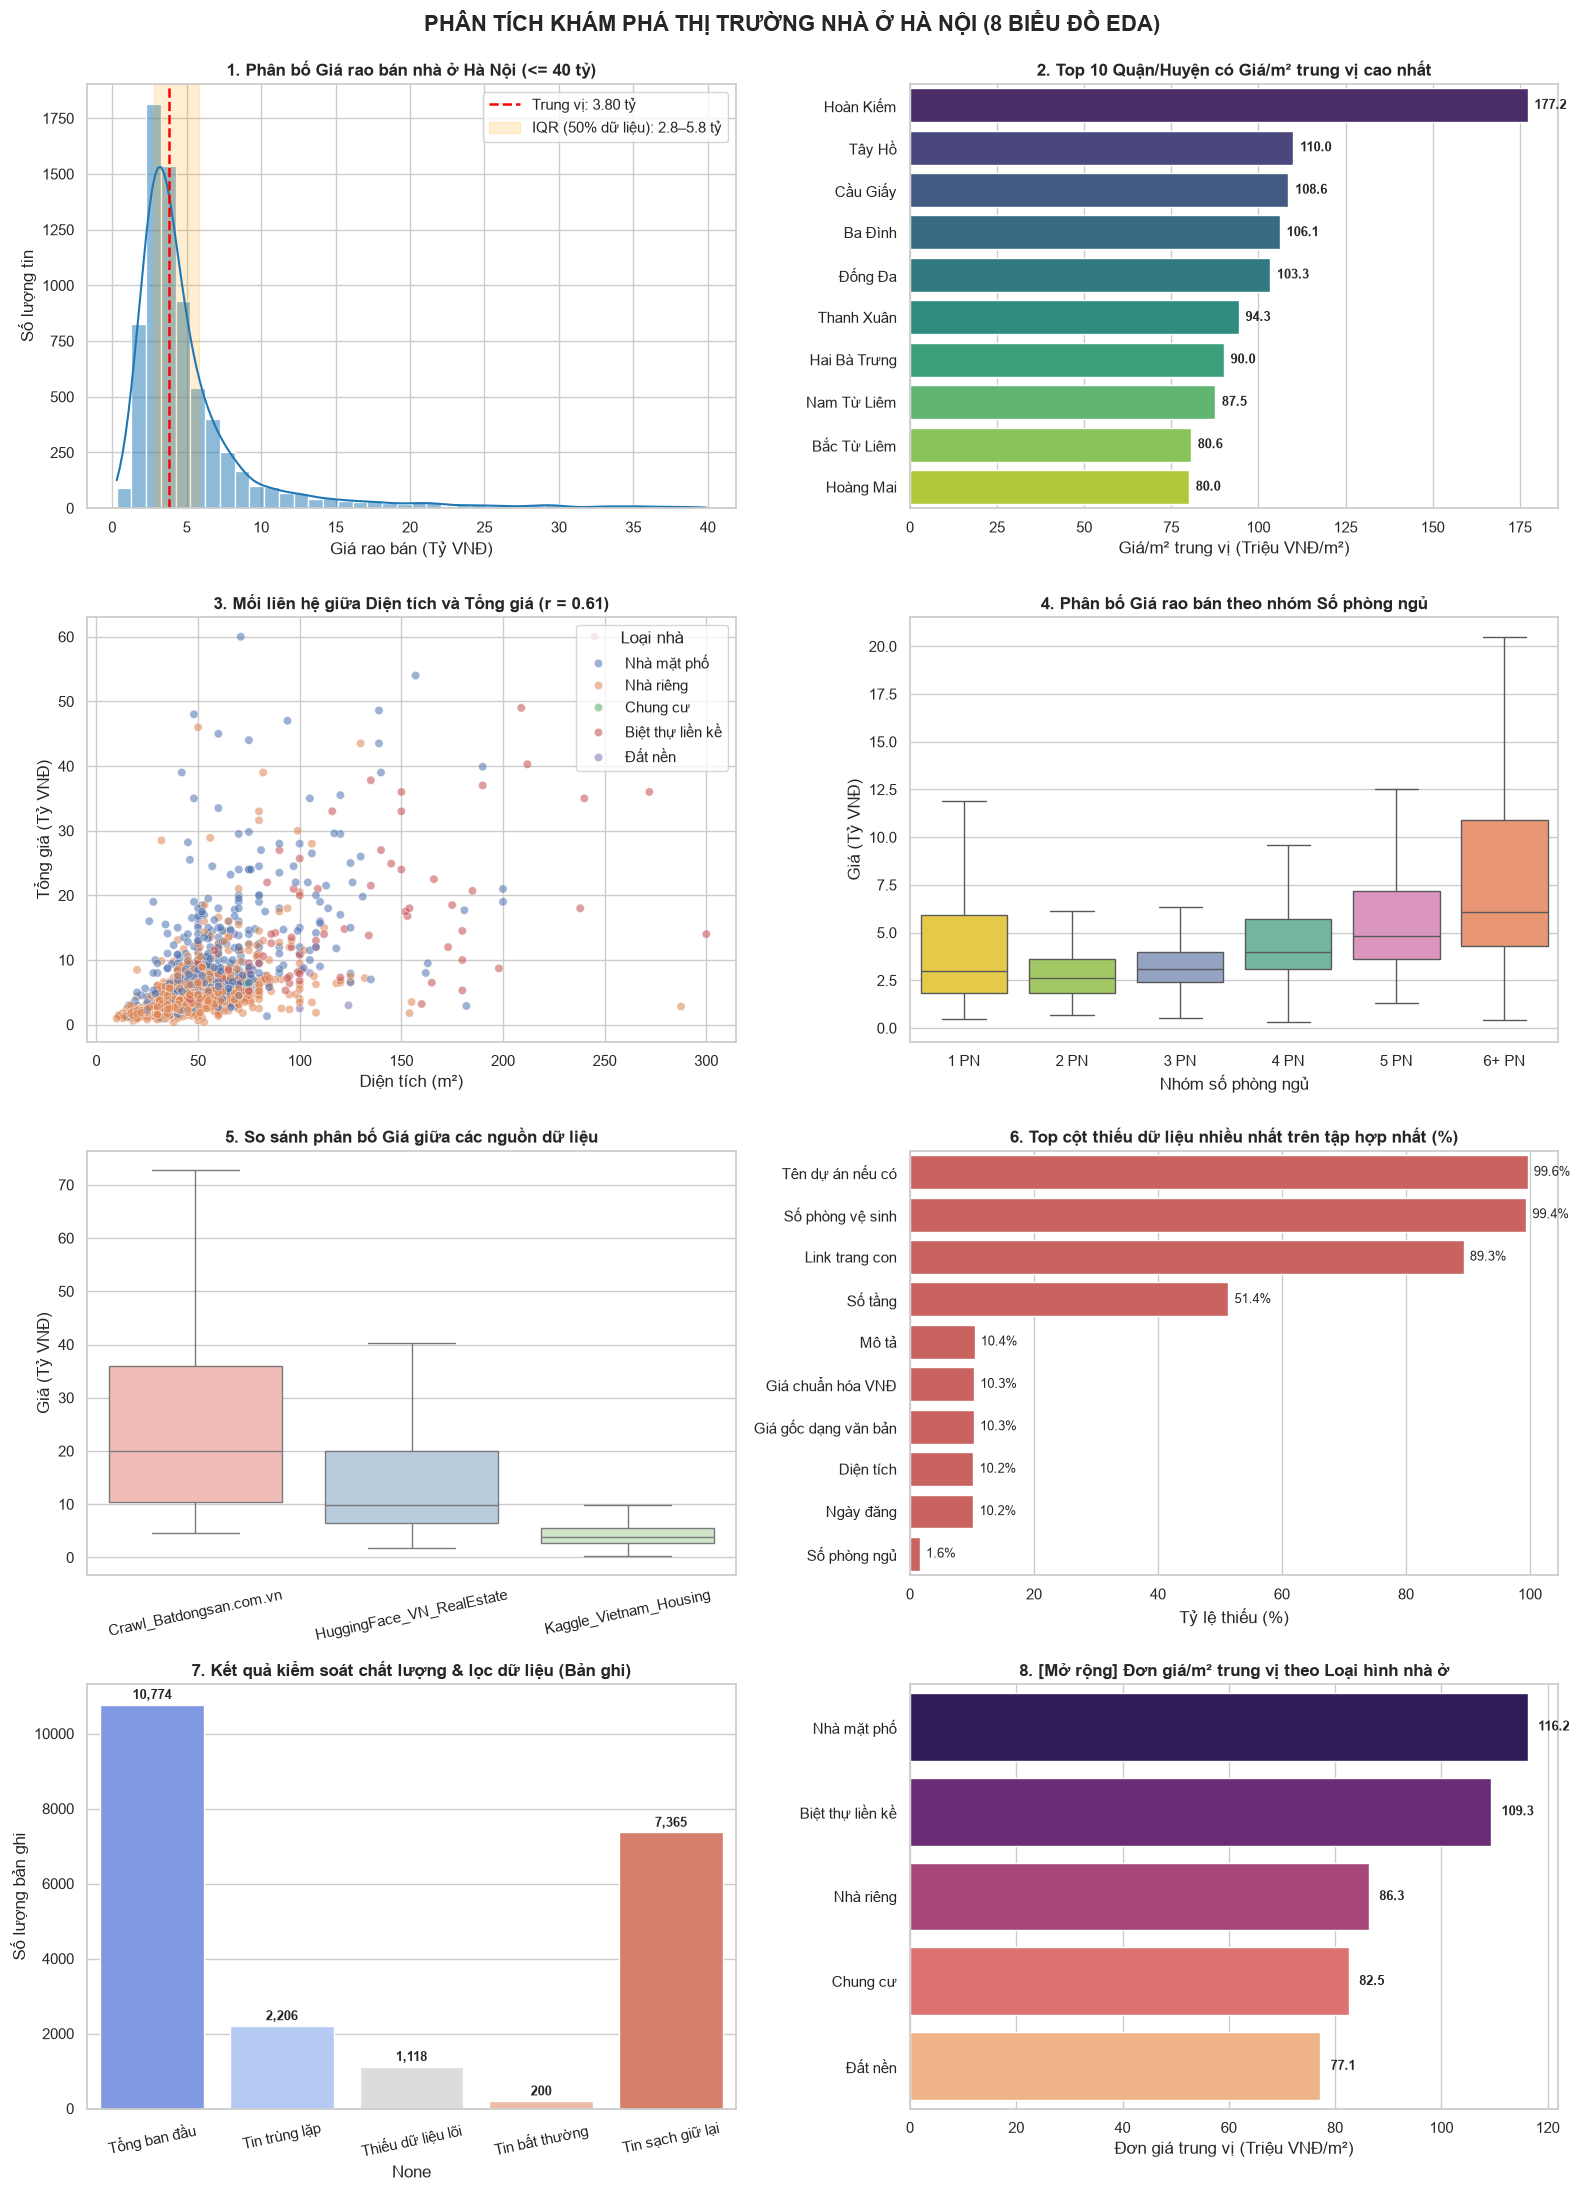

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid")

# 1. Tự động nạp dữ liệu từ Cell 1 (hoặc đọc lại từ file nếu vừa khởi động lại Kernel)
proc_dir = "../Data/processed" if os.path.exists("../Data/processed") else "Data/processed"
if "df_all" not in globals():
    df_all = pd.read_excel(os.path.join(proc_dir, "hanoi_housing_data.xlsx"), sheet_name="Du_Lieu_Nha_O_Ha_Noi")
if "df_clean" not in globals():
    df_clean = pd.read_csv(os.path.join(proc_dir, "hanoi_housing_cleaned.csv"))
else:
    df_clean = df_clean.copy()

df_clean["Giá (Tỷ VNĐ)"] = df_clean["Giá chuẩn hóa VNĐ"] / 1e9
df_clean["Đơn giá (Triệu/m²)"] = (df_clean["Giá chuẩn hóa VNĐ"] / df_clean["Diện tích"]) / 1e6

# ==============================================================================
# 2. IN BÁO CÁO SỐ LIỆU TRẢ LỜI TRỌN VẸN 8 CÂU HỎI ĐỀ BÀI
# ==============================================================================
q25, q50, q75 = df_clean["Giá (Tỷ VNĐ)"].quantile([0.25, 0.50, 0.75])

top_dist = (
    df_clean.groupby("Khu vực/Quận huyện theo nguồn")["Đơn giá (Triệu/m²)"]
    .agg(["count", "median"])
    .query("count >= 15")
    .sort_values("median", ascending=False)
)

corr_area_price = df_clean["Diện tích"].corr(df_clean["Giá (Tỷ VNĐ)"])

df_clean["Nhóm phòng ngủ"] = df_clean["Số phòng ngủ"].apply(
    lambda x: f"{int(x)} PN" if pd.notna(x) and x <= 5 else ("6+ PN" if pd.notna(x) else "Không rõ")
)
order_pn = [p for p in ["1 PN", "2 PN", "3 PN", "4 PN", "5 PN", "6+ PN"] if p in df_clean["Nhóm phòng ngủ"].unique()]
bed_stats = df_clean[df_clean["Nhóm phòng ngủ"].isin(order_pn)].groupby("Nhóm phòng ngủ")["Giá (Tỷ VNĐ)"].median().reindex(order_pn)

src_stats = df_clean.groupby("Nguồn dữ liệu")["Giá (Tỷ VNĐ)"].agg(["count", "median", "mean"])
missing_pct = (df_all.isna().mean() * 100).sort_values(ascending=False)
type_stats = df_clean.groupby("Loại nhà")["Đơn giá (Triệu/m²)"].median().sort_values(ascending=False)

print("=" * 80)
print("BÁO CÁO PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA) - TRẢ LỜI 8 CÂU HỎI ĐỀ BÀI")
print("=" * 80)
print(f"1. Khoảng giá rao bán chủ yếu (IQR 25% - 75%): {q25:.2f} tỷ – {q75:.2f} tỷ VNĐ (Trung vị: {q50:.2f} tỷ VNĐ).")
print(f"2. Khu vực có giá/m² trung vị cao nhất: {top_dist.index[0]} ({top_dist['median'].iloc[0]:.1f} triệu/m²).")
print(f"3. Tương quan giữa Diện tích và Tổng giá: r = {corr_area_price:.3f} (tương quan thuận).")
print("4. Giá trung vị (Tỷ VNĐ) theo nhóm số phòng ngủ:")
print("   " + " | ".join([f"{k}: {v:.2f} tỷ" for k, v in bed_stats.items()]))
print("5. Phân bố giá (Tỷ VNĐ) giữa các nguồn dữ liệu:")
print(src_stats.round(2).to_string())
print(f"6. Cột thiếu nhiều dữ liệu nhất (trên {len(df_all):,} dòng hợp nhất): '{missing_pct.index[0]}' ({missing_pct.iloc[0]:.1f}%).")
print(f"7. Kết quả lọc chất lượng: Ban đầu {len(df_all):,} | Trùng lặp: {df_all['Cờ trùng lặp'].sum():,} | "
      f"Thiếu dữ liệu: {df_all['Cờ thiếu dữ liệu'].sum():,} | Bất thường: {df_all['Cờ bất thường'].sum():,} -> Giữ lại {len(df_clean):,} tin sạch.")
print("8. [Mở rộng] Đơn giá/m² trung vị theo Loại nhà:")
print("   " + " | ".join([f"{k}: {v:.1f} tr/m²" for k, v in type_stats.items()]))

# ==============================================================================
# 3. VẼ TRỌN BỘ 8 BIỂU ĐỒ TRỰC QUAN HÓA (4 HÀNG × 2 CỘT)
# ==============================================================================
fig, axes = plt.subplots(4, 2, figsize=(16, 22))
fig.suptitle("PHÂN TÍCH KHÁM PHÁ THỊ TRƯỜNG NHÀ Ở HÀ NỘI (8 BIỂU ĐỒ EDA)", fontsize=16, fontweight="bold", y=0.995)

# Biểu đồ 1: Giá rao bán chủ yếu nằm trong khoảng nào?
sns.histplot(df_clean[df_clean["Giá (Tỷ VNĐ)"] <= 40]["Giá (Tỷ VNĐ)"], bins=40, kde=True, ax=axes[0, 0], color="#1f77b4")
axes[0, 0].axvline(q50, color="red", linestyle="--", lw=1.8, label=f"Trung vị: {q50:.2f} tỷ")
axes[0, 0].axvspan(q25, q75, color="orange", alpha=0.18, label=f"IQR (50% dữ liệu): {q25:.1f}–{q75:.1f} tỷ")
axes[0, 0].set_title("1. Phân bố Giá rao bán nhà ở Hà Nội (<= 40 tỷ)", fontweight="bold")
axes[0, 0].set_xlabel("Giá rao bán (Tỷ VNĐ)")
axes[0, 0].set_ylabel("Số lượng tin")
axes[0, 0].legend()

# Biểu đồ 2: Khu vực nào có giá/m² trung vị cao nhất?
top10_dist = top_dist.head(10).reset_index()
sns.barplot(
    data=top10_dist, x="median", y="Khu vực/Quận huyện theo nguồn",
    hue="Khu vực/Quận huyện theo nguồn", legend=False, palette="viridis", ax=axes[0, 1]
)
axes[0, 1].set_title("2. Top 10 Quận/Huyện có Giá/m² trung vị cao nhất", fontweight="bold")
axes[0, 1].set_xlabel("Giá/m² trung vị (Triệu VNĐ/m²)")
axes[0, 1].set_ylabel("")
for i, v in enumerate(top10_dist["median"]):
    axes[0, 1].text(v + 2, i, f"{v:.1f}", va="center", fontsize=9, fontweight="bold")

# Biểu đồ 3: Diện tích liên quan thế nào đến tổng giá?
sample_plot = df_clean[(df_clean["Diện tích"] <= 300) & (df_clean["Giá (Tỷ VNĐ)"] <= 60)].sample(
    min(2500, len(df_clean)), random_state=42
)
sns.scatterplot(data=sample_plot, x="Diện tích", y="Giá (Tỷ VNĐ)", hue="Loại nhà", alpha=0.55, ax=axes[1, 0])
axes[1, 0].set_title(f"3. Mối liên hệ giữa Diện tích và Tổng giá (r = {corr_area_price:.2f})", fontweight="bold")
axes[1, 0].set_xlabel("Diện tích (m²)")
axes[1, 0].set_ylabel("Tổng giá (Tỷ VNĐ)")

# Biểu đồ 4: Giá khác nhau thế nào giữa các nhóm số phòng ngủ?
df_pn_plot = df_clean[df_clean["Nhóm phòng ngủ"].isin(order_pn)]
sns.boxplot(
    data=df_pn_plot, x="Nhóm phòng ngủ", y="Giá (Tỷ VNĐ)", order=order_pn,
    hue="Nhóm phòng ngủ", legend=False, showfliers=False, palette="Set2", ax=axes[1, 1]
)
axes[1, 1].set_title("4. Phân bố Giá rao bán theo nhóm Số phòng ngủ", fontweight="bold")
axes[1, 1].set_xlabel("Nhóm số phòng ngủ")
axes[1, 1].set_ylabel("Giá (Tỷ VNĐ)")

# Biểu đồ 5: Dữ liệu từ các nguồn có phân bố giá khác nhau không?
sns.boxplot(
    data=df_clean, x="Nguồn dữ liệu", y="Giá (Tỷ VNĐ)",
    hue="Nguồn dữ liệu", legend=False, showfliers=False, palette="Pastel1", ax=axes[2, 0]
)
axes[2, 0].set_title("5. So sánh phân bố Giá giữa các nguồn dữ liệu", fontweight="bold")
axes[2, 0].set_xlabel("")
axes[2, 0].set_ylabel("Giá (Tỷ VNĐ)")
axes[2, 0].tick_params(axis="x", rotation=12)

# Biểu đồ 6: Cột nào thiếu nhiều dữ liệu nhất?
top_miss = missing_pct[missing_pct > 0].head(10)
sns.barplot(x=top_miss.values, y=top_miss.index, color="#d9534f", ax=axes[2, 1])
axes[2, 1].set_title("6. Top cột thiếu dữ liệu nhiều nhất trên tập hợp nhất (%)", fontweight="bold")
axes[2, 1].set_xlabel("Tỷ lệ thiếu (%)")
axes[2, 1].set_ylabel("")
for i, v in enumerate(top_miss.values):
    axes[2, 1].text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)

# Biểu đồ 7: Sau xử lý đã loại bao nhiêu tin trùng, tin lỗi?
flag_summary = pd.Series({
    "Tổng ban đầu": len(df_all),
    "Tin trùng lặp": int(df_all["Cờ trùng lặp"].sum()),
    "Thiếu dữ liệu lõi": int(df_all["Cờ thiếu dữ liệu"].sum()),
    "Tin bất thường": int(df_all["Cờ bất thường"].sum()),
    "Tin sạch giữ lại": len(df_clean),
})
sns.barplot(
    x=flag_summary.index, y=flag_summary.values,
    hue=flag_summary.index, legend=False, palette="coolwarm", ax=axes[3, 0]
)
axes[3, 0].set_title("7. Kết quả kiểm soát chất lượng & lọc dữ liệu (Bản ghi)", fontweight="bold")
axes[3, 0].set_ylabel("Số lượng bản ghi")
axes[3, 0].tick_params(axis="x", rotation=12)
for i, v in enumerate(flag_summary.values):
    axes[3, 0].text(i, v + 150, f"{v:,}", ha="center", fontsize=9, fontweight="bold")

# Biểu đồ 8: [Tự thiết kế] Đơn giá/m² trung vị theo Loại hình nhà ở
sns.barplot(
    x=type_stats.values, y=type_stats.index,
    hue=type_stats.index, legend=False, palette="magma", ax=axes[3, 1]
)
axes[3, 1].set_title("8. [Mở rộng] Đơn giá/m² trung vị theo Loại hình nhà ở", fontweight="bold")
axes[3, 1].set_xlabel("Đơn giá trung vị (Triệu VNĐ/m²)")
axes[3, 1].set_ylabel("")
for i, v in enumerate(type_stats.values):
    axes[3, 1].text(v + 2, i, f"{v:.1f}", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
chart_path = os.path.join(proc_dir, "eda_8_charts.png")
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
print(f"\n🖼️ Đã lưu trọn bộ 8 biểu đồ EDA tại: {chart_path}")
plt.show()